# Dubai Metro ridership: dataset profile

Rerunnable checks on the raw export, before any pipeline work. Every table is saved to `results/profile/` and every chart to `figures/`.

Raw files are read from `data/raw/`; set `METRO_DATA_DIR` if they live elsewhere. `assert` lines stop the run if a number changes.

In [1]:
import os
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

ROOT_DATA = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data" / "raw"
DATA_DIR = Path(os.environ.get("METRO_DATA_DIR", ROOT_DATA))
RIDERSHIP = DATA_DIR / "metro_ridership_2026-07-21_18-21-58_0001.csv"
STATIONS = DATA_DIR / "metro_stations_2026-09-21_17-40-59_0001.csv"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "profile"
FIGURES = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Team decisions, 5 Nov 2026
WINDOWS = [("W17/18", "2017-11", "2018-02"), ("W18/19", "2018-09", "2019-02"),
           ("W19/20", "2019-09", "2020-02"), ("W21/22", "2021-09", "2022-02"),
           ("W24/25", "2024-09", "2025-02")]
MIN_TAPS = 300
SENSITIVITY_TAPS = 100
BANDS = [("00-07", 0, 7), ("07-10", 7, 10), ("10-16", 10, 16), ("16-20", 16, 20), ("20-24", 20, 24)]

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
pd.set_option("display.width", 200, "display.max_rows", 120, "display.max_columns", 30)

con = duckdb.connect()
q = lambda sql: con.execute(sql).df()
def save(df, name):
    df.to_csv(RESULTS / f"{name}.csv", index=False)
    return df

## 1. Load the raw file
All columns are read as text, so nothing is silently converted.

In [2]:
con.execute(f"""
create table raw as
select row_number() over () as rn, *,
       substr(txn_date, 1, 4) as yr,
       substr(txn_date, 1, 7) as ym,
       txn_time like '00:00:00%' as date_only,
       cast(substr(txn_time, 1, 2) as int) as hr,
       cast(txn_date as date) as dt,
       regexp_replace(trim(replace(end_location, ' Metro Station', '')), '\s+', ' ', 'g') as raw_name
from read_csv('{RIDERSHIP.as_posix()}', all_varchar=true, header=true, quote='"')
""")
con.execute(f"create table st as select * from read_csv('{STATIONS.as_posix()}', all_varchar=true, header=true, quote='\"')")
overview = q("select count(*) as n_rows, min(txn_date) as first_date, max(txn_date) as last_date, count(distinct txn_date) as n_dates from raw")
assert overview.n_rows[0] == 1_048_468
overview

,n_rows,first_date,last_date,n_dates
0,1048468,2017-01-01,2026-07-11,3343


## 2. Which column gives the tap station?
Decision: `end_location` for all rows.

In [3]:
tap_station = save(q("""
select txn_type, count(*) as n_rows,
       sum((start_location is null)::int) as start_missing,
       sum((end_location is null)::int) as end_missing,
       sum((start_location is null and end_location is null)::int) as both_missing,
       sum((start_location <> end_location)::int) as columns_disagree
from raw group by 1 order by 1"""), "tap_station_columns")
assert tap_station.end_missing.sum() == 942 == tap_station.both_missing.sum()
tap_station

,txn_type,n_rows,start_missing,end_missing,both_missing,columns_disagree
0,Check in,529344,51955.0,274.0,274.0,475.0
1,Check out,519124,447937.0,668.0,668.0,0.0


## 3. Where do real tap times exist?
A day is either fully timed or fully date-only. Outlined cells are the five chosen windows.

,yr,n_rows,timed_rows,pct_date_only
0,2017,132052,19587.0,85.2
1,2018,132489,96281.0,27.3
2,2019,145214,115714.0,20.3
3,2020,77289,18891.0,75.6
4,2021,115558,51891.0,55.1
5,2022,72163,42555.0,41.0
6,2023,50377,0.0,100.0
7,2024,116478,61102.0,47.5
8,2025,154949,37748.0,75.6
9,2026,51899,19746.0,62.0


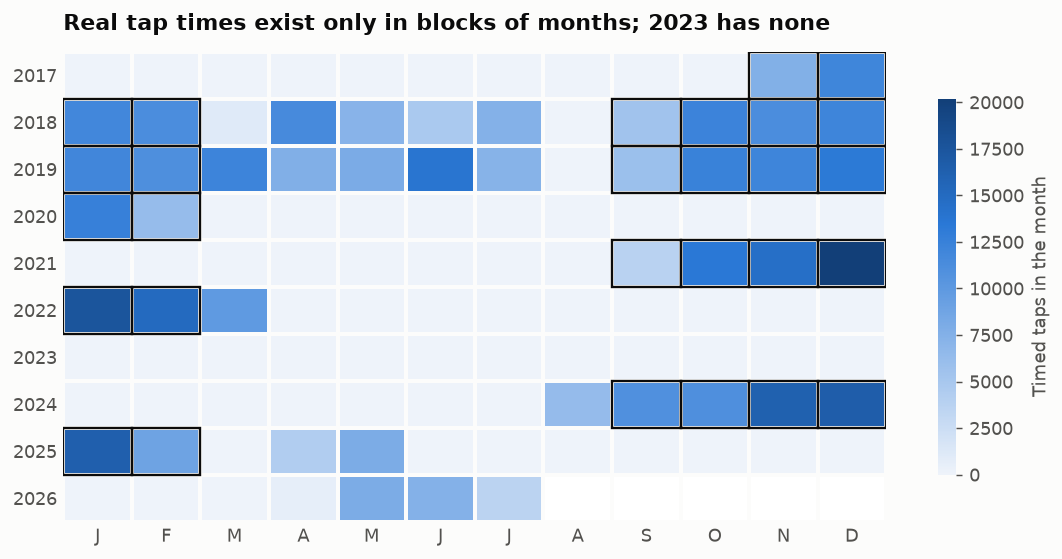

In [4]:
by_year = save(q("""
select yr, count(*) as n_rows, sum((not date_only)::int) as timed_rows,
       round(100.0 * avg(date_only::int), 1) as pct_date_only
from raw group by 1 order by 1"""), "rows_by_year")
months = save(q("""
select yr, cast(substr(ym, 6, 2) as int) as month, count(*) as n_rows, sum((not date_only)::int) as timed_rows
from raw group by 1, 2 order by 1, 2"""), "rows_by_month")
assert by_year.set_index("yr").timed_rows["2023"] == 0

grid = months.pivot(index="yr", columns="month", values="timed_rows")
cmap = LinearSegmentedColormap.from_list("seq", ["#eef3fa", "#8fb8ea", BLUE, "#123f78"])
cmap.set_bad("#ffffff")
fig, ax = plt.subplots(figsize=(8.6, 4.4))
im = ax.pcolormesh(grid.values, cmap=cmap, edgecolors=SURFACE, linewidth=2, vmin=0)
ax.invert_yaxis()
ax.set_xticks([i + .5 for i in range(12)], ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks([i + .5 for i in range(len(grid))], grid.index)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
years = list(grid.index)
for _, a, b in WINDOWS:
    for p in pd.period_range(a, b, freq="M"):
        ax.add_patch(Rectangle((p.month - 1, years.index(str(p.year))), 1, 1, fill=False, ec=INK, lw=1.3))
ax.set_title("Real tap times exist only in blocks of months; 2023 has none", loc="left", fontsize=12, fontweight="bold", pad=12)
fig.colorbar(im, ax=ax, label="Timed taps in the month", shrink=.8).outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "profile_timed_months.png", dpi=200)
by_year

## 4. Sampling is uneven inside years
The share of each year's rows falling in January to April shows why raw counts cannot be compared across time.

In [5]:
skew = save(q("""
select yr, count(*) as n_rows,
       round(100.0 * avg((substr(ym, 6, 2) <= '04')::int), 1) as pct_jan_apr
from raw where yr < '2026' group by 1 order by 1"""), "sampling_skew")
skew

,yr,n_rows,pct_jan_apr
0,2017,132052,34.1
1,2018,132489,33.4
2,2019,145214,32.2
3,2020,77289,42.6
4,2021,115558,24.2
5,2022,72163,86.3
6,2023,50377,10.9
7,2024,116478,17.8
8,2025,154949,39.4


## 5. The June 2025 format change
Check-ins pull away from check-outs in the same months that `start_location` starts being filled on check-outs.

,ym,n_rows,checkin_per_checkout,pct_checkouts_with_start
99,2025-04,13349,1.073,52.1
100,2025-05,13447,1.104,61.9
101,2025-06,11452,1.163,100.0
102,2025-07,10491,1.177,100.0
103,2025-08,10652,1.169,100.0
104,2025-09,10689,1.163,100.0
105,2025-10,12776,1.176,100.0
106,2025-11,12438,1.173,100.0
107,2025-12,11909,1.170,100.0
108,2026-01,11127,1.165,100.0


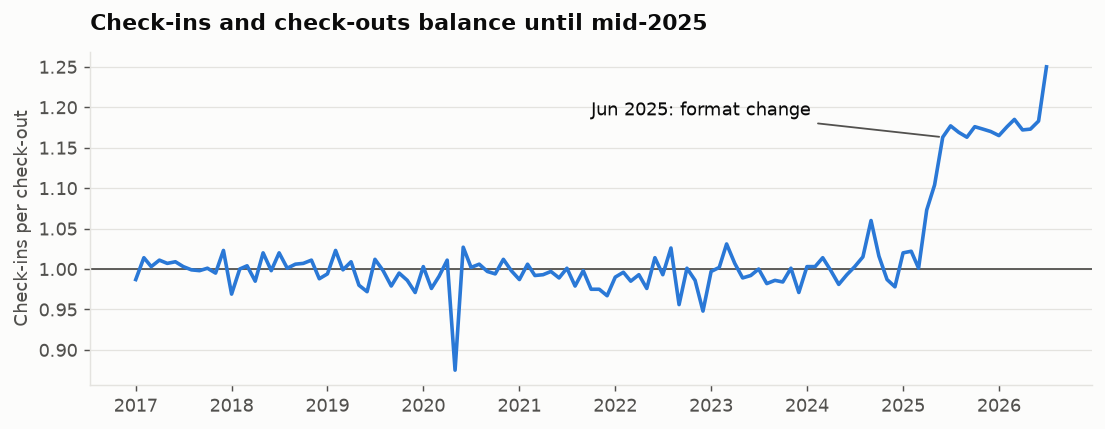

In [6]:
ratio = save(q("""
select ym, count(*) as n_rows,
       round(1.0 * sum((txn_type = 'Check in')::int) / sum((txn_type <> 'Check in')::int), 3) as checkin_per_checkout,
       round(100.0 * sum((txn_type <> 'Check in' and start_location is not null)::int)
             / sum((txn_type <> 'Check in')::int), 1) as pct_checkouts_with_start
from raw group by 1 order by 1"""), "checkin_checkout_ratio")
x = pd.to_datetime(ratio.ym)
fig, ax = plt.subplots(figsize=(8.6, 3.4))
ax.axhline(1, color=MUTED, lw=1)
ax.plot(x, ratio.checkin_per_checkout, color=BLUE, lw=2)
ax.grid(axis="y", color=GRID, lw=.7)
ax.set_ylabel("Check-ins per check-out")
ax.annotate("Jun 2025: format change", (pd.Timestamp("2025-06-01"), 1.163), xytext=(pd.Timestamp("2021-10-01"), 1.19),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_title("Check-ins and check-outs balance until mid-2025", loc="left", fontsize=12, fontweight="bold", pad=12)
fig.tight_layout()
fig.savefig(FIGURES / "profile_checkin_ratio.png", dpi=200)
ratio.tail(16)

## 6. Draft station map: (raw name, line) to `location_id`
Renames are **inferred from handover dates in the data and are not yet confirmed against RTA**. This draft is input for `station_name_map.csv`.

`Sharaf DG` needs the line: Red is the station now called Mashreq, Green is the former Al Fahidi.

In [7]:
renamed = {  # raw name -> stations-file location_id
    "centrepoint": 128, "City Centre Deira": 133, "max": 138,
    "Al Safa": 146, "ONPASSIVE": 146,
    "FGB": 148, "Umm Al Sheif": 148, "Equiti": 148,
    "Al Khail": 152, "Dubai Marina": 153, "Sobha Realty": 153,
    "Jumeirah Lakes Towers": 154, "Nakheel Harbour & Tower": 155,
    "Palm Deira": 171, "etisalat by e&": 160}
sharaf = {"Red Metro Line": 150, "Green Metro Line": 174}
current_name = {128: "centrepoint", 133: "City Centre Deira", 138: "max", 146: "ONPASSIVE", 148: "Equiti",
                150: "Mashreq", 152: "Al Khail", 153: "Sobha Realty", 154: "DMCC", 155: "Jabal Ali",
                160: "Etisalat", 171: "Gold Souq", 174: "Sharaf DG"}

stations = q("select location_id, location_name_english as name, line_name from st")
stations["location_id"] = stations.location_id.astype(int)
stations["name"] = (stations.name.str.replace(" Metro Station", "", regex=False)
                    .str.replace(r"\s+", " ", regex=True).str.strip())
red_first = stations.sort_values("line_name", key=lambda s: s.str.startswith("Green"))
by_name = red_first.drop_duplicates("name").set_index("name").location_id.to_dict()
names = dict(zip(stations.location_id, stations.name))

pairs = q("""
select raw_name, line_name, count(*) as n_rows, min(txn_date) as first_seen, max(txn_date) as last_seen
from raw where raw_name is not null group by 1, 2 order by 1, 2""")
def to_id(r):
    if r.raw_name == "Sharaf DG":
        return sharaf[r.line_name]
    return renamed.get(r.raw_name, by_name.get(r.raw_name))
pairs["location_id"] = pairs.apply(to_id, axis=1)
assert pairs.location_id.notna().all(), pairs[pairs.location_id.isna()]
pairs["location_id"] = pairs.location_id.astype(int)
pairs["station"] = pairs.location_id.map(lambda i: current_name.get(i, names[i]))
pairs["match"] = pairs.apply(lambda r: "exact" if by_name.get(r.raw_name) == r.location_id else "inferred", axis=1)
save(pairs, "station_map_draft")
con.register("station_map", pairs[["raw_name", "line_name", "location_id", "station"]])
print(pairs.raw_name.nunique(), "raw names ->", pairs.location_id.nunique(), "stations;", (pairs.match == "inferred").sum(), "inferred pairs")
assert pairs.location_id.nunique() == 53
pairs[pairs.match == "inferred"].sort_values(["location_id", "first_seen"])

69 raw names -> 53 stations; 17 inferred pairs


,raw_name,line_name,n_rows,first_seen,last_seen,location_id,station,match
72,centrepoint,Red Metro Line,13383,2021-08-08,2026-07-11,128,centrepoint,inferred
22,City Centre Deira,Red Metro Line,12410,2022-04-17,2026-07-11,133,City Centre Deira,inferred
74,max,Red Metro Line,9768,2019-06-18,2026-07-11,138,max,inferred
17,Al Safa,Red Metro Line,6017,2020-11-29,2023-01-07,146,ONPASSIVE,inferred
57,ONPASSIVE,Red Metro Line,11095,2023-01-09,2026-07-11,146,ONPASSIVE,inferred
42,FGB,Red Metro Line,2424,2017-01-01,2017-12-30,148,Equiti,inferred
69,Umm Al Sheif,Red Metro Line,2941,2020-11-29,2022-04-16,148,Equiti,inferred
40,Equiti,Red Metro Line,6614,2022-04-17,2026-07-11,148,Equiti,inferred
63,Sharaf DG,Red Metro Line,6627,2017-01-01,2020-05-02,150,Mashreq,inferred
11,Al Khail,Red Metro Line,3258,2020-11-29,2026-07-11,152,Al Khail,inferred


## 7. Coverage of the five windows
Decision: timed taps only, at least 300 per station-window, with 100 as the sensitivity check.

In [8]:
case = " ".join(f"when ym between '{a}' and '{b}' then '{n}'" for n, a, b in WINDOWS)
con.execute(f"""
create table taps as
select r.*, m.location_id, m.station, case {case} end as win
from raw r join station_map m
  on r.raw_name = m.raw_name and r.line_name is not distinct from m.line_name
where not r.date_only
""")
con.execute("delete from taps where win is null")
points = save(q("""
select win, location_id, station, count(*) as timed_taps,
       sum((txn_type = 'Check in')::int) as check_ins, sum((txn_type <> 'Check in')::int) as check_outs
from taps group by 1, 2, 3 order by 1, 3"""), "station_windows")
coverage = save(points.groupby("win").agg(
    stations=("station", "size"), timed_taps=("timed_taps", "sum"),
    pass_300=("timed_taps", lambda s: (s >= MIN_TAPS).sum()),
    pass_100=("timed_taps", lambda s: (s >= SENSITIVITY_TAPS).sum()),
    median_taps=("timed_taps", "median"),
    checkin_per_checkout=("check_ins", "sum")).reset_index(), "window_coverage")
coverage["checkin_per_checkout"] = (coverage.checkin_per_checkout / points.groupby("win").check_outs.sum().values).round(3)
save(coverage, "window_coverage")
print("Points at 300:", coverage.pass_300.sum(), "| at 100:", coverage.pass_100.sum())
assert coverage.pass_300.sum() == 227 and coverage.pass_100.sum() == 239
coverage

Points at 300: 227 | at 100: 239


,win,stations,timed_taps,pass_300,pass_100,median_taps,checkin_per_checkout
0,W17/18,47,42664,42,45,766.0,0.997
1,W18/19,46,64090,43,45,1114.5,1.004
2,W19/20,46,62555,43,45,1073.5,0.985
3,W21/22,53,84192,49,51,1243.0,0.987
4,W24/25,53,80053,50,53,1225.0,1.010


In [9]:
weak = save(points.assign(ok=points.timed_taps >= MIN_TAPS).groupby("station").agg(
    windows_present=("win", "size"), windows_passing=("ok", "sum")).reset_index()
    .query("windows_passing < windows_present").sort_values("windows_passing"), "stations_below_threshold")
weak

,station,windows_present,windows_passing
30,Energy,5,0
37,Jabal Ali,3,0
38,Jumeirah Golf Estates,2,0
19,Creek,5,1
7,Al Jadaf,5,2
8,Al Khail,5,4


## 8. Are the five time bands well filled?
Median taps per cell, for retained points. A cell is one station-window, band and tap direction.

In [10]:
band_case = " ".join(f"when hr >= {lo} and hr < {hi} then '{n}'" for n, lo, hi in BANDS)
con.execute(f"create table banded as select *, case {band_case} end as band from taps")
keep = points[points.timed_taps >= MIN_TAPS][["win", "location_id"]]
con.register("keep", keep)
cells = save(q("""
with c as (
  select b.win, b.location_id, txn_type, band, count(*) as n
  from banded b join keep k on b.win = k.win and b.location_id = k.location_id
  group by all)
select band, cast(median(n) as int) as median_taps, sum((n < 5)::int) as cells_under_5,
       count(*) as cells_filled, 2 * (select count(*) from keep) as cells_expected
from c group by 1 order by 1"""), "band_cells")
cells

,band,median_taps,cells_under_5,cells_filled,cells_expected
0,00-07,24,24.0,452,454
1,07-10,98,0.0,454,454
2,10-16,152,0.0,454,454
3,16-20,194,0.0,454,454
4,20-24,108,0.0,454,454


## 9. Do the features carry real behaviour?
Net flow is (check-ins - check-outs) / (check-ins + check-outs), pooled over the five windows. Positive means more people leave from the station.

band,station,07-10,16-20
0,Burj Khalifa/ Dubai Mall,-0.678,0.089
1,Business Bay,-0.622,0.491
2,Emirates Towers,-0.331,0.286
3,Dubai Internet City,-0.278,0.252
4,Al Qusais,-0.247,0.263
5,Financial Centre,-0.129,0.113
6,Mall of the Emirates,0.128,-0.079
7,centrepoint,0.228,-0.019
8,Airport Terminal 3,0.241,0.117
9,Etisalat,0.307,-0.159


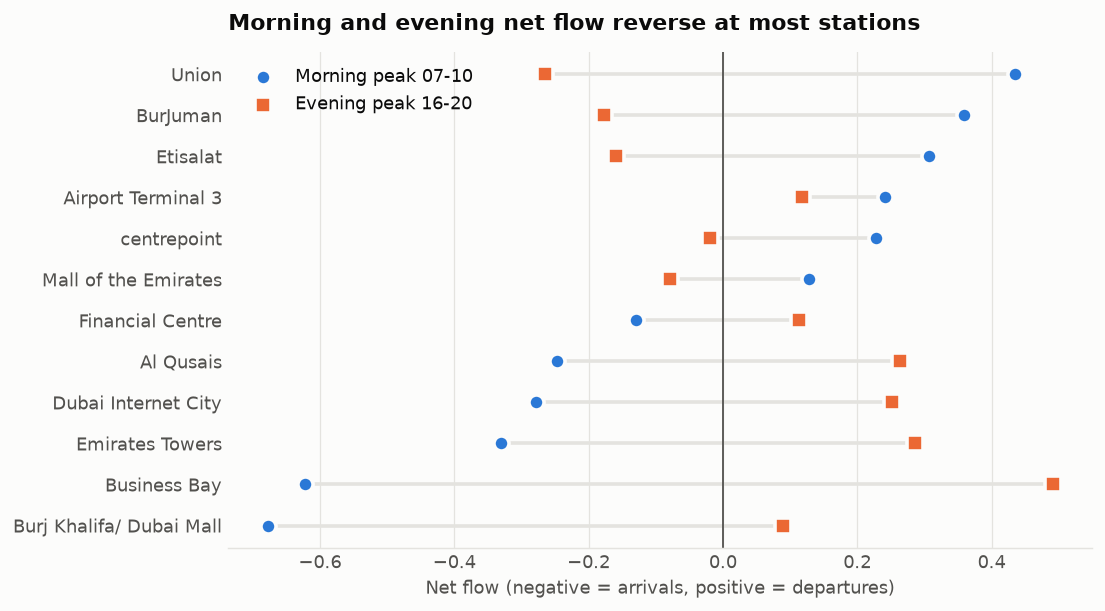

In [11]:
known = ["Business Bay", "Burj Khalifa/ Dubai Mall", "Emirates Towers", "Dubai Internet City", "Financial Centre",
         "Al Qusais", "Mall of the Emirates", "centrepoint", "Etisalat", "Airport Terminal 3", "BurJuman", "Union"]
flow = q("""
select station, band, sum((txn_type = 'Check in')::int) as ci, sum((txn_type <> 'Check in')::int) as co
from banded where band in ('07-10', '16-20') group by 1, 2""")
flow = flow[flow.station.isin(known)].assign(net=lambda d: (d.ci - d.co) / (d.ci + d.co))
flow = save(flow.pivot(index="station", columns="band", values="net").round(3).sort_values("07-10").reset_index(), "net_flow_known_stations")

fig, ax = plt.subplots(figsize=(8.6, 4.8))
y = range(len(flow))
ax.axvline(0, color=MUTED, lw=1)
ax.hlines(y, flow["07-10"], flow["16-20"], color=GRID, lw=2, zorder=1)
ax.scatter(flow["07-10"], y, s=70, color=BLUE, edgecolor=SURFACE, lw=2, label="Morning peak 07-10", zorder=3)
ax.scatter(flow["16-20"], y, s=70, color=ORANGE, marker="s", edgecolor=SURFACE, lw=2, label="Evening peak 16-20", zorder=3)
ax.set_yticks(list(y), flow.station)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Net flow (negative = arrivals, positive = departures)")
ax.grid(axis="x", color=GRID, lw=.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Morning and evening net flow reverse at most stations", loc="left", fontsize=12, fontweight="bold", pad=12)
fig.tight_layout()
fig.savefig(FIGURES / "profile_net_flow.png", dpi=200)
flow

## 10. Friday and weekend checks
Band features use all days by decision. This table records how different Friday is across windows, for the report's limitations.

In [12]:
friday = save(q("""
select win,
  round(100.0 * sum((dayname(dt) = 'Friday' and hr < 10)::int) / sum((dayname(dt) = 'Friday')::int), 1) as friday_pct_before_10,
  round(100.0 * sum((dayname(dt) in ('Monday','Tuesday','Wednesday','Thursday') and hr < 10)::int)
        / sum((dayname(dt) in ('Monday','Tuesday','Wednesday','Thursday'))::int), 1) as mon_thu_pct_before_10
from taps group by 1 order by 1"""), "friday_check")
weekdays = save(q("""
select case when yr <= '2021' then 'to 2021' else 'from 2022' end as era, dayname(dt) as weekday,
       round(1.0 * count(*) / count(distinct dt), 0) as rows_per_day
from raw group by 1, 2 order by 1 desc, 3"""), "weekday_volume")
display(friday)
weekdays

,win,friday_pct_before_10,mon_thu_pct_before_10
0,W17/18,1.7,24.8
1,W18/19,2.9,25.9
2,W19/20,2.7,24.9
3,W21/22,12.8,20.1
4,W24/25,25.5,25.3


,era,weekday,rows_per_day
0,to 2021,Friday,258.0
1,to 2021,Saturday,289.0
2,to 2021,Wednesday,353.0
3,to 2021,Monday,353.0
4,to 2021,Tuesday,356.0
5,to 2021,Sunday,360.0
6,to 2021,Thursday,388.0
7,from 2022,Sunday,224.0
8,from 2022,Saturday,271.0
9,from 2022,Thursday,294.0
